# Baselines on the deduplicated graphs

> **Derived notebook.** Generated by `code/python/scripts/derive_corrected_notebooks.py` from `baseline_retraining_factorial_protocol_colab.ipynb`. Edit the generator, not this file. See `docs/fair-comparison-corrected.md`.

Run after the factorial notebook with the same `LABEL_MODE` and `SPLIT_MODE`; this notebook reads its manifest,
alignment, seeds, parameters (including the recomputed output bias) and results.
`RUN_MODELS` selects the baselines: `['MLP']` by default; add `'E-GraphSAGE'`, `'Edge GRU'` or
`'Static GNN'` for a wider comparison. Paired Test 1 differences use `M1_P1` when it was trained,
otherwise `M1_P0`. Training, threshold and champion code are unchanged from the historical notebook.


In [1]:
import importlib.util
import json
import subprocess
import sys
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/nids-mitre')
LABEL_MODE = 'original'      # must match the factorial run
SPLIT_MODE = 'historical'    # must match the factorial run
FACTORIAL_ROOT = DRIVE_ROOT / f'results_stgnn_factorial_dedup_{SPLIT_MODE}_split_{LABEL_MODE}_v1'
OUTPUT = DRIVE_ROOT / f'results_baselines_dedup_{SPLIT_MODE}_split_{LABEL_MODE}_v1'
CLONE_DIR = Path('/content/temporalgnn-nids-baseline-retraining')
ALLOW_ENVIRONMENT_DIFFERENCES = False
RETRY_FAILED = False
VERIFY_GRAPH_HASHES = True
NUM_WORKERS = 2

reference_path = FACTORIAL_ROOT / 'manifest.json'
assert reference_path.is_file(), f'Missing completed factorial manifest: {reference_path}'
for filename in ('test1_all_seeds.csv', 'test2_champions.csv'):
    assert (FACTORIAL_ROOT / filename).is_file(), f'Missing completed factorial table: {filename}'
reference_manifest = json.loads(reference_path.read_text())
SOURCE_COMMIT = reference_manifest['source_commit']
assert SOURCE_COMMIT == '2262b53d155f9e8cf5221516f47e4170e6cd0d6e'
reference_software = reference_manifest['software']
for module, requirement in [
    ('torch_geometric', 'torch_geometric==' + reference_software['pyg']),
    ('pyarrow', 'pyarrow'),
]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', requirement], check=True)

if not CLONE_DIR.exists():
    subprocess.run(['git', 'clone', '--no-checkout',
                    'https://github.com/tatipar/temporalgnn-nids.git', str(CLONE_DIR)], check=True)
subprocess.run(['git', '-C', str(CLONE_DIR), 'fetch', '--depth', '1',
                'origin', SOURCE_COMMIT], check=True)
subprocess.run(['git', '-C', str(CLONE_DIR), 'checkout', '--detach', SOURCE_COMMIT], check=True)
actual_commit = subprocess.check_output(
    ['git', '-C', str(CLONE_DIR), 'rev-parse', 'HEAD'], text=True).strip()
assert actual_commit == SOURCE_COMMIT
sys.path.insert(0, str(CLONE_DIR / 'code/python'))
print('Pinned implementation:', actual_commit)

Mounted at /content/drive
Pinned implementation: 2262b53d155f9e8cf5221516f47e4170e6cd0d6e


In [2]:
import gc
import hashlib
import os
import platform
import time
import traceback
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
import torch.nn as nn
import torch_geometric
from IPython.display import display
from matplotlib.lines import Line2D
from sklearn.metrics import average_precision_score
from torch_geometric.loader import DataLoader

from utils.datasets import NF_IDS_Dataset
from utils.models import SimpleMLP, E_GraphSAGE, EdgeGRU_Baseline_NoX, StaticGNN_Identity
from utils.training import train_epoch, evaluate, find_optimal_threshold, set_seed
from utils.experiment import EarlyStopping, NumpyEncoder
from utils.metrics import calculate_metrics_gnn
from utils.evaluation import apply_1sd_rule

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WINDOW_SECONDS = 30
SEEDS = list(reference_manifest['seeds'])
PARAMS = dict(reference_manifest['model_params'])
TRAINING = dict(reference_manifest['training'])
ALERT_BUDGET_FRACTION = float(reference_manifest['ranking_budget_fraction'])
N_SEEDS = 5   # must not exceed the seeds completed by the factorial run (minimal check: 3)
PROTOCOL_SEEDS = SEEDS
SEEDS = PROTOCOL_SEEDS[:N_SEEDS]
assert PROTOCOL_SEEDS == [42, 123, 777, 2024, 99] and 1 <= N_SEEDS <= 5
assert reference_manifest['labels'] == f'{LABEL_MODE}_binary_dedup'
assert all(m['split_mode'] == SPLIT_MODE for m in reference_manifest['build_manifests'].values())
# The output bias is recomputed per label mode by the factorial notebook (logit of prevalence).
assert {k: v for k, v in PARAMS.items() if k != 'output_bias_init'} == dict(
    node_dim=16, edge_dim=32, hidden_dim=32, dropout=0.2)
assert TRAINING == dict(epochs=60, batch_steps=10, learning_rate=0.005,
                        pos_weight=2.0, patience=10, min_delta=0.0001)

# Stable order: finish all five seeds of one model before the next model.
MODEL_SPECS = {
    'MLP': dict(constructor='SimpleMLP', folder='mlp', temporal=False),
    'E-GraphSAGE': dict(constructor='E_GraphSAGE', folder='e_graphsage', temporal=False),
    'Edge GRU': dict(constructor='EdgeGRU_Baseline_NoX', folder='edge_gru', temporal=True),
    'Static GNN': dict(constructor='StaticGNN_Identity', folder='static_gnn', temporal=False),
}
RUN_MODELS = ['MLP']   # add 'E-GraphSAGE', 'Edge GRU', 'Static GNN' for the wider comparison
assert set(RUN_MODELS) <= set(MODEL_SPECS), RUN_MODELS
PROTOCOL_MODEL_SPECS = dict(MODEL_SPECS)   # frozen in the manifest; RUN_MODELS selects this session
MODEL_SPECS = {name: spec for name, spec in MODEL_SPECS.items() if name in RUN_MODELS}
CONSTRUCTORS = dict(SimpleMLP=SimpleMLP, E_GraphSAGE=E_GraphSAGE,
                     EdgeGRU_Baseline_NoX=EdgeGRU_Baseline_NoX,
                     StaticGNN_Identity=StaticGNN_Identity)

def make_model(name):
    return CONSTRUCTORS[MODEL_SPECS[name]['constructor']](**PARAMS)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def json_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, cls=NumpyEncoder).encode()).hexdigest()

def write_json(path, value):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, cls=NumpyEncoder, allow_nan=False))
    os.replace(tmp, path)

def cleanup():
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

REFERENCE_MANIFEST_SHA256 = json_digest(reference_manifest)
current_software = dict(python=platform.python_version(), torch=str(torch.__version__),
                         pyg=str(torch_geometric.__version__), numpy=np.__version__, pandas=pd.__version__)
environment = pd.DataFrame({'factorial': reference_software, 'current': current_software})
environment['matches'] = environment['factorial'] == environment['current']
display(environment)
if not ALLOW_ENVIRONMENT_DIFFERENCES:
    assert environment['matches'].all(), (
        'Restore the recorded factorial software environment before training, or explicitly '
        'set ALLOW_ENVIRONMENT_DIFFERENCES=True to record a different environment. '
        'Restart Colab after changing an imported package version.')

OUTPUT.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'none')
print('Training order:', list(MODEL_SPECS))
print('New output:', OUTPUT)

,factorial,current,matches
python,3.13.18,3.13.18,True
torch,2.11.0+cpu,2.11.0+cpu,True
pyg,2.8.1,2.8.1,True
numpy,2.4.6,2.4.6,True
pandas,2.2.3,2.2.3,True


Device: cpu | GPU: none
Training order: ['MLP']
New output: /content/drive/MyDrive/nids-mitre/results_baselines_dedup_historical_split_original_v1


## 1. Reuse the exact graph partitions and alignment

The factorial notebook already created flow indices and graph inventories. This notebook
loads those artifacts rather than rebuilding them or scanning tensors to recreate indices.
By default it verifies the original graph bytes against the inventories before training.
Each partition prints a start and completion message, even if it has fewer than 500 graphs.
The first/last times below are graph-window starts. Wednesday train, validation, and Test 1
are distinct existing directories with the same capture date. Numeric host IDs are scoped
to their capture day.

In [3]:
SPLITS, datasets, loaders = {}, {}, {}
alignment, graph_inventories, split_manifest = {}, {}, {}
for tag in ('train', 'val', 'test1', 'test2'):
    spec = reference_manifest['splits'][tag]
    root, split, day = Path(spec['root']), spec['directory'], spec['capture_day']
    SPLITS[tag] = (root, split, day)
    assert (root / split).is_dir(), f'Missing graph partition: {root / split}'
    index_path = FACTORIAL_ROOT / 'alignment' / f'{tag}_flows.parquet'
    inventory_path = FACTORIAL_ROOT / 'alignment' / f'{tag}_graphs.csv'
    assert sha256_file(index_path) == spec['alignment_sha256']
    assert sha256_file(inventory_path) == spec['inventory_sha256']
    index = pd.read_parquet(index_path)
    graphs = pd.read_csv(inventory_path)
    dataset = NF_IDS_Dataset(root_dir=str(root), split=split)
    assert dataset.files == graphs['file'].tolist(), f'Graph file list changed: {tag}'
    assert len(dataset) == spec['graphs'] and len(index) == spec['flows']
    assert int(index['label'].sum()) == spec['attacks']
    assert np.array_equal(index['flow_index'].to_numpy(), np.arange(len(index)))
    assert not index.duplicated(['window_id', 'edge_index_in_graph']).any()
    assert index['graph_number'].between(0, len(graphs) - 1).all()
    assert int(graphs['edges'].sum()) == len(index)
    print(f'{tag}: verifying {len(dataset)} saved graphs from {root / split}')
    if VERIFY_GRAPH_HASHES:
        for number, graph_row in enumerate(graphs.itertuples(index=False), start=1):
            graph_path = root / split / graph_row.file
            assert graph_path.stat().st_size == graph_row.bytes, graph_path
            assert sha256_file(graph_path) == graph_row.sha256, f'Graph content changed: {graph_path}'
            if number % 500 == 0:
                print(f'  {tag}: verified {number}/{len(dataset)} files')
    print(f'  {tag}: complete | {len(index):,} flows | {int(index.label.sum()):,} attacks')
    datasets[tag], alignment[tag], graph_inventories[tag] = dataset, index, graphs
    split_manifest[tag] = dict(spec)
    loaders[tag] = DataLoader(dataset, batch_size=1, shuffle=False,
                              num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0,
                              pin_memory=False)

assert pd.Timestamp(split_manifest['train']['last_window']) < pd.Timestamp(split_manifest['val']['first_window'])
assert pd.Timestamp(split_manifest['val']['last_window']) < pd.Timestamp(split_manifest['test1']['first_window'])
# Split counts were checked against the build manifests by the factorial notebook.
assert all(split_manifest[tag]['attacks'] > 0 for tag in split_manifest)
display(pd.DataFrame(split_manifest).T[
    ['directory', 'capture_day', 'first_window', 'last_window', 'graphs', 'flows', 'attacks']])

parameter_rows = []
for name, spec in MODEL_SPECS.items():
    set_seed(SEEDS[0])
    model = make_model(name)
    parameter_rows.append(dict(model=name, **spec,
                                total_parameters=sum(p.numel() for p in model.parameters()),
                                trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad)))
    del model
parameter_counts = pd.DataFrame(parameter_rows)

source_files = ['models.py', 'training.py', 'datasets.py', 'metrics.py', 'evaluation.py', 'experiment.py']
source_hashes = {f'code/python/utils/{name}': sha256_file(CLONE_DIR / 'code/python/utils' / name)
                 for name in source_files}
for name, digest in source_hashes.items():
    assert digest == reference_manifest['pinned_source_hashes'][name], f'Pinned source differs: {name}'
manifest = dict(
    notebook_version='baseline_retraining_factorial_protocol_v1', source_commit=SOURCE_COMMIT,
    reference_factorial_root=str(FACTORIAL_ROOT), reference_manifest_sha256=REFERENCE_MANIFEST_SHA256,
    reference_manifest_file_sha256=sha256_file(reference_path),
    seeds=PROTOCOL_SEEDS, model_params=PARAMS, training=TRAINING, models=PROTOCOL_MODEL_SPECS,
    pinned_source_hashes=source_hashes, splits=split_manifest,
    labels=reference_manifest['labels'], graph_version=reference_manifest['graph_version'],
    ranking_budget_fraction=ALERT_BUDGET_FRACTION,
    threshold_rule=reference_manifest['threshold_rule'],
    champion_rule=reference_manifest['champion_rule'],
    memory_policy='Edge_GRU_empty_at_each_epoch_and_split; no_warmup',
    software=current_software, sklearn_version=sklearn.__version__,
    environment_matches_factorial=bool(environment['matches'].all()),
    allow_environment_differences=ALLOW_ENVIRONMENT_DIFFERENCES,
    verify_graph_hashes=VERIFY_GRAPH_HASHES,
    loader=dict(batch_size=1, shuffle=False, num_workers=NUM_WORKERS,
                persistent_workers=NUM_WORKERS > 0, pin_memory=False),
)
MANIFEST_SHA256 = json_digest(manifest)
manifest_path = OUTPUT / 'manifest.json'
if manifest_path.exists():
    assert json.loads(manifest_path.read_text()) == manifest, (
        'Output configuration or software changed. Restore the saved settings or use a new OUTPUT.')
else:
    write_json(manifest_path, manifest)
parameter_counts.to_csv(OUTPUT / 'parameter_counts.csv', index=False)
for name, spec in MODEL_SPECS.items():
    write_json(OUTPUT / f'config_{spec["folder"]}.json', dict(
        model=name, implementation=spec, seeds=SEEDS, model_params=PARAMS, training=TRAINING,
        manifest_sha256=MANIFEST_SHA256,
        parameters=parameter_counts.loc[parameter_counts.model == name].to_dict('records')[0]))
runtime = dict(utc=datetime.now(timezone.utc).isoformat(), device=str(DEVICE),
               gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
               cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
               manifest_sha256=MANIFEST_SHA256)
write_json(OUTPUT / 'runtime.json', runtime)
reference_runtime_path = FACTORIAL_ROOT / 'runtime.json'
if reference_runtime_path.exists():
    reference_runtime = json.loads(reference_runtime_path.read_text())
    display(pd.DataFrame({'factorial': {k: reference_runtime.get(k) for k in ('device', 'gpu', 'cuda', 'cudnn')},
                          'baseline_retraining': {k: runtime[k] for k in ('device', 'gpu', 'cuda', 'cudnn')}}))
display(parameter_counts)

train: verifying 1998 saved graphs from /content/drive/MyDrive/nids-mitre/dataset_processed_dedup_historical_original/train
  train: verified 500/1998 files
  train: verified 1000/1998 files
  train: verified 1500/1998 files
  train: complete | 1,020,151 flows | 33,783 attacks
val: verifying 428 saved graphs from /content/drive/MyDrive/nids-mitre/dataset_processed_dedup_historical_original/val
  val: complete | 775,940 flows | 22,212 attacks
test1: verifying 429 saved graphs from /content/drive/MyDrive/nids-mitre/dataset_processed_dedup_historical_original/test
  test1: complete | 190,206 flows | 2,167 attacks
test2: verifying 2822 saved graphs from /content/drive/MyDrive/nids-mitre/dataset_processed_thu0103_dedup_historical_original/test2
  test2: verified 500/2822 files
  test2: verified 1000/2822 files
  test2: verified 1500/2822 files
  test2: verified 2000/2822 files
  test2: verified 2500/2822 files
  test2: complete | 2,074,036 flows | 57,350 attacks


,directory,capture_day,first_window,last_window,graphs,flows,attacks
train,train,2018-02-28,2018-02-28T00:12:55.854000,2018-02-28T16:51:25.854000,1998,1020151,33783
val,val,2018-02-28,2018-02-28T16:51:55.854000,2018-02-28T20:25:25.854000,428,775940,22212
test1,test,2018-02-28,2018-02-28T20:25:55.854000,2018-02-28T23:59:55.854000,429,190206,2167
test2,test2,2018-03-01,2018-03-01T00:00:03.289000,2018-03-01T23:30:33.289000,2822,2074036,57350


,factorial,baseline_retraining
device,cpu,cpu
gpu,None,None
cuda,None,None
cudnn,None,None


,model,constructor,folder,temporal,total_parameters,trainable_parameters
0,MLP,SimpleMLP,mlp,False,2273,2273


## 2. Train four baselines across five seeds

Use the same pinned `train_epoch`, `evaluate`, `find_optimal_threshold`, and `EarlyStopping`
functions as the factorial run. The temporal interface is explicit: only Edge GRU receives
global node IDs and stores state. Every model accumulates losses over the same 10 windows.
The original per-window loss reduction, final-segment handling, and threshold tie convention
are retained for protocol continuity. No optimizer/scheduler/loss changes are introduced.

Checkpoints are selected by validation AP. The record stores a zero-based `best_epoch`,
matching the original project; progress messages display it as `best_epoch + 1`.
History is saved after each epoch, but it is not an optimizer-resume checkpoint.
The completion record is written after the checkpoint and aligned validation scores.

In [ ]:
def run_paths(name, seed):
    folder = OUTPUT / MODEL_SPECS[name]['folder'] / f'seed_{seed}'
    return folder, folder / 'checkpoint.pth', folder / 'record.json'

def read_record(name, seed):
    folder, checkpoint, path = run_paths(name, seed)
    if not path.exists():
        return None
    record = json.loads(path.read_text())
    assert record['model'] == name and record['seed'] == seed
    assert record['manifest_sha256'] == MANIFEST_SHA256
    if record['status'] == 'complete':
        assert checkpoint.is_file() and sha256_file(checkpoint) == record['checkpoint_sha256']
        assert (folder / 'val_scores.npz').is_file()
    return record

def train_one(name, seed):
    previous = read_record(name, seed)
    if previous is not None and (previous['status'] == 'complete' or not RETRY_FAILED):
        print(name, 'seed', seed, ': retaining', previous['status'])
        return previous
    folder, checkpoint, record_path = run_paths(name, seed)
    folder.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    started = time.perf_counter()
    history = []
    temporal = MODEL_SPECS[name]['temporal']
    model = optimizer = criterion = stopper = None
    base_record = dict(model=name, seed=seed, temporal=temporal,
                       run_id=f'{MODEL_SPECS[name]["folder"]}_seed{seed}',
                       manifest_sha256=MANIFEST_SHA256, source_commit=SOURCE_COMMIT)
    try:
        model = make_model(name).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=TRAINING['learning_rate'])
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([TRAINING['pos_weight']], device=DEVICE))
        stopper = EarlyStopping(patience=TRAINING['patience'], min_delta=TRAINING['min_delta'], mode='max')
        for epoch in range(TRAINING['epochs']):
            epoch_start = time.perf_counter()
            train_loss = train_epoch(model, loaders['train'], optimizer, criterion, DEVICE,
                                     is_temporal=temporal, batch_steps=TRAINING['batch_steps'])
            val_loss, labels, probabilities = evaluate(
                model, loaders['val'], criterion, DEVICE, is_temporal=temporal)
            assert np.array_equal(labels, alignment['val'].label.to_numpy())
            val_ap = float(average_precision_score(labels, probabilities))
            if not (np.isfinite([train_loss, val_loss, val_ap]).all() and np.isfinite(probabilities).all()):
                raise FloatingPointError('Nonfinite loss or validation scores')
            improved = stopper(val_ap, model, epoch)
            history.append(dict(epoch=epoch + 1, train_loss=float(train_loss), val_loss=float(val_loss),
                                val_ap=val_ap, seconds=time.perf_counter() - epoch_start))
            pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
            if improved or (epoch + 1) % 10 == 0:
                print(f'{name} seed {seed} | epoch {epoch + 1}: train={train_loss:.4f}, '
                      f'val AP={val_ap:.4f}' + (' *' if improved else ''))
            if stopper.early_stop:
                break
        assert stopper.best_model_state is not None
        model.load_state_dict(stopper.best_model_state, strict=True)
        threshold, labels, probabilities = find_optimal_threshold(
            model, loaders['val'], DEVICE, is_temporal=temporal, strategy='max_f1')
        assert np.array_equal(labels, alignment['val'].label.to_numpy())
        assert np.isfinite(threshold) and np.isfinite(probabilities).all()
        metrics = calculate_metrics_gnn(labels, probabilities, prob_threshold=float(threshold))
        assert np.isfinite(list(metrics.values())).all()
        if temporal:
            model.reset_memory()
        tmp_checkpoint = folder / 'checkpoint.pth.tmp'
        torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, tmp_checkpoint)
        os.replace(tmp_checkpoint, checkpoint)
        checkpoint_hash = sha256_file(checkpoint)
        metadata = dict(split='val', model=name, seed=seed, checkpoint_sha256=checkpoint_hash,
                        threshold=float(threshold), manifest_sha256=MANIFEST_SHA256,
                        alignment_sha256=split_manifest['val']['alignment_sha256'],
                        dataset_sha256=split_manifest['val']['dataset_sha256'])
        tmp_scores = folder / 'val_scores.tmp.npz'
        np.savez_compressed(tmp_scores, flow_index=alignment['val'].flow_index.to_numpy(),
                            probabilities=probabilities.astype(np.float32), metadata=np.array(json.dumps(metadata)))
        os.replace(tmp_scores, folder / 'val_scores.npz')
        record = dict(**base_record, status='complete', threshold=float(threshold),
                      best_epoch=int(stopper.best_epoch), stopped_epoch=len(history),
                      best_val_ap=float(stopper.best_score), val_metrics=metrics,
                      checkpoint_sha256=checkpoint_hash, seconds=time.perf_counter() - started)
        write_json(record_path, record)
        print(name, 'seed', seed, ': complete; best epoch', record['best_epoch'] + 1,
              '| validation AP', metrics['AUC-PR'])
        return record
    except Exception as error:
        record = dict(**base_record, status='failed', error_type=type(error).__name__,
                      error=str(error), traceback=traceback.format_exc(), completed_epochs=len(history),
                      seconds=time.perf_counter() - started)
        write_json(record_path, record)
        print(name, 'seed', seed, ': FAILED:', type(error).__name__, str(error))
        return record
    finally:
        if model is not None and temporal:
            model.reset_memory()
        del model, optimizer, criterion, stopper
        cleanup()

training_status_rows = []
for name in MODEL_SPECS:
    for seed in SEEDS:
        record = train_one(name, seed)
        training_status_rows.append(dict(model=name, seed=seed, status=record['status'],
                                         error=record.get('error', '')))
        pd.DataFrame(training_status_rows).to_csv(OUTPUT / 'training_status.csv', index=False)
training_status = pd.DataFrame(training_status_rows)
display(training_status)

MLP seed 42 | epoch 1: train=0.1549, val AP=0.0673 *
MLP seed 42 | epoch 2: train=0.1511, val AP=0.0754 *
MLP seed 42 | epoch 3: train=0.1523, val AP=0.1619 *
MLP seed 42 | epoch 5: train=0.1463, val AP=0.1743 *
MLP seed 42 | epoch 7: train=0.1529, val AP=0.1765 *
MLP seed 42 | epoch 8: train=0.1482, val AP=0.1784 *
MLP seed 42 | epoch 10: train=0.1473, val AP=0.1871 *
MLP seed 42 | epoch 18: train=0.1463, val AP=0.1916 *
MLP seed 42 | epoch 20: train=0.1460, val AP=0.1904
MLP seed 42 | epoch 24: train=0.1447, val AP=0.1963 *
MLP seed 42 | epoch 29: train=0.1430, val AP=0.1980 *
MLP seed 42 | epoch 30: train=0.1418, val AP=0.2054 *
MLP seed 42 | epoch 32: train=0.1403, val AP=0.2084 *
MLP seed 42 | epoch 34: train=0.1397, val AP=0.2104 *
MLP seed 42 | epoch 36: train=0.1391, val AP=0.2106 *
MLP seed 42 | epoch 38: train=0.1389, val AP=0.2184 *
MLP seed 42 | epoch 40: train=0.1383, val AP=0.2174
MLP seed 42 | epoch 41: train=0.1381, val AP=0.2247 *
MLP seed 42 | epoch 43: train=0.1372, 

KeyboardInterrupt: 

In [4]:
def run_paths(name, seed):
    folder = OUTPUT / MODEL_SPECS[name]['folder'] / f'seed_{seed}'
    return folder, folder / 'checkpoint.pth', folder / 'record.json'

def read_record(name, seed):
    folder, checkpoint, path = run_paths(name, seed)
    if not path.exists():
        return None
    record = json.loads(path.read_text())
    assert record['model'] == name and record['seed'] == seed
    assert record['manifest_sha256'] == MANIFEST_SHA256
    if record['status'] == 'complete':
        assert checkpoint.is_file() and sha256_file(checkpoint) == record['checkpoint_sha256']
        assert (folder / 'val_scores.npz').is_file()
    return record

def train_one(name, seed):
    previous = read_record(name, seed)
    if previous is not None and (previous['status'] == 'complete' or not RETRY_FAILED):
        print(name, 'seed', seed, ': retaining', previous['status'])
        return previous
    folder, checkpoint, record_path = run_paths(name, seed)
    folder.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    started = time.perf_counter()
    history = []
    temporal = MODEL_SPECS[name]['temporal']
    model = optimizer = criterion = stopper = None
    base_record = dict(model=name, seed=seed, temporal=temporal,
                       run_id=f'{MODEL_SPECS[name]["folder"]}_seed{seed}',
                       manifest_sha256=MANIFEST_SHA256, source_commit=SOURCE_COMMIT)
    try:
        model = make_model(name).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=TRAINING['learning_rate'])
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([TRAINING['pos_weight']], device=DEVICE))
        stopper = EarlyStopping(patience=TRAINING['patience'], min_delta=TRAINING['min_delta'], mode='max')
        for epoch in range(TRAINING['epochs']):
            epoch_start = time.perf_counter()
            train_loss = train_epoch(model, loaders['train'], optimizer, criterion, DEVICE,
                                     is_temporal=temporal, batch_steps=TRAINING['batch_steps'])
            val_loss, labels, probabilities = evaluate(
                model, loaders['val'], criterion, DEVICE, is_temporal=temporal)
            assert np.array_equal(labels, alignment['val'].label.to_numpy())
            val_ap = float(average_precision_score(labels, probabilities))
            if not (np.isfinite([train_loss, val_loss, val_ap]).all() and np.isfinite(probabilities).all()):
                raise FloatingPointError('Nonfinite loss or validation scores')
            improved = stopper(val_ap, model, epoch)
            history.append(dict(epoch=epoch + 1, train_loss=float(train_loss), val_loss=float(val_loss),
                                val_ap=val_ap, seconds=time.perf_counter() - epoch_start))
            pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
            if improved or (epoch + 1) % 10 == 0:
                print(f'{name} seed {seed} | epoch {epoch + 1}: train={train_loss:.4f}, '
                      f'val AP={val_ap:.4f}' + (' *' if improved else ''))
            if stopper.early_stop:
                break
        assert stopper.best_model_state is not None
        model.load_state_dict(stopper.best_model_state, strict=True)
        threshold, labels, probabilities = find_optimal_threshold(
            model, loaders['val'], DEVICE, is_temporal=temporal, strategy='max_f1')
        assert np.array_equal(labels, alignment['val'].label.to_numpy())
        assert np.isfinite(threshold) and np.isfinite(probabilities).all()
        metrics = calculate_metrics_gnn(labels, probabilities, prob_threshold=float(threshold))
        assert np.isfinite(list(metrics.values())).all()
        if temporal:
            model.reset_memory()
        tmp_checkpoint = folder / 'checkpoint.pth.tmp'
        torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, tmp_checkpoint)
        os.replace(tmp_checkpoint, checkpoint)
        checkpoint_hash = sha256_file(checkpoint)
        metadata = dict(split='val', model=name, seed=seed, checkpoint_sha256=checkpoint_hash,
                        threshold=float(threshold), manifest_sha256=MANIFEST_SHA256,
                        alignment_sha256=split_manifest['val']['alignment_sha256'],
                        dataset_sha256=split_manifest['val']['dataset_sha256'])
        tmp_scores = folder / 'val_scores.tmp.npz'
        np.savez_compressed(tmp_scores, flow_index=alignment['val'].flow_index.to_numpy(),
                            probabilities=probabilities.astype(np.float32), metadata=np.array(json.dumps(metadata)))
        os.replace(tmp_scores, folder / 'val_scores.npz')
        record = dict(**base_record, status='complete', threshold=float(threshold),
                      best_epoch=int(stopper.best_epoch), stopped_epoch=len(history),
                      best_val_ap=float(stopper.best_score), val_metrics=metrics,
                      checkpoint_sha256=checkpoint_hash, seconds=time.perf_counter() - started)
        write_json(record_path, record)
        print(name, 'seed', seed, ': complete; best epoch', record['best_epoch'] + 1,
              '| validation AP', metrics['AUC-PR'])
        return record
    except Exception as error:
        record = dict(**base_record, status='failed', error_type=type(error).__name__,
                      error=str(error), traceback=traceback.format_exc(), completed_epochs=len(history),
                      seconds=time.perf_counter() - started)
        write_json(record_path, record)
        print(name, 'seed', seed, ': FAILED:', type(error).__name__, str(error))
        return record
    finally:
        if model is not None and temporal:
            model.reset_memory()
        del model, optimizer, criterion, stopper
        cleanup()

training_status_rows = []
for name in MODEL_SPECS:
    for seed in SEEDS:
        record = train_one(name, seed)
        training_status_rows.append(dict(model=name, seed=seed, status=record['status'],
                                         error=record.get('error', '')))
        pd.DataFrame(training_status_rows).to_csv(OUTPUT / 'training_status.csv', index=False)
training_status = pd.DataFrame(training_status_rows)
display(training_status)

MLP seed 42 : retaining complete
MLP seed 123 : retaining complete
MLP seed 777 : retaining complete
MLP seed 2024 : retaining complete
MLP seed 99 | epoch 1: train=0.1537, val AP=0.0519 *
MLP seed 99 | epoch 2: train=0.1524, val AP=0.0558 *
MLP seed 99 | epoch 3: train=0.1536, val AP=0.1379 *
MLP seed 99 | epoch 4: train=0.1547, val AP=0.1600 *
MLP seed 99 | epoch 5: train=0.1503, val AP=0.1613 *
MLP seed 99 | epoch 7: train=0.1488, val AP=0.1704 *
MLP seed 99 | epoch 9: train=0.1481, val AP=0.1741 *
MLP seed 99 | epoch 10: train=0.1481, val AP=0.1734
MLP seed 99 | epoch 14: train=0.1468, val AP=0.1872 *
MLP seed 99 | epoch 20: train=0.1458, val AP=0.1692

Optimal Threshold: 0.1638 (Max F1)
MLP seed 99 : complete; best epoch 14 | validation AP 0.18724844501304902


,model,seed,status,error
0,MLP,42,complete,
1,MLP,123,complete,
2,MLP,777,complete,
3,MLP,2024,complete,
4,MLP,99,complete,


The following training cell resumes from records saved by the preceding attempt.


In [5]:
def run_paths(name, seed):
    folder = OUTPUT / MODEL_SPECS[name]['folder'] / f'seed_{seed}'
    return folder, folder / 'checkpoint.pth', folder / 'record.json'

def read_record(name, seed):
    folder, checkpoint, path = run_paths(name, seed)
    if not path.exists():
        return None
    record = json.loads(path.read_text())
    assert record['model'] == name and record['seed'] == seed
    assert record['manifest_sha256'] == MANIFEST_SHA256
    if record['status'] == 'complete':
        assert checkpoint.is_file() and sha256_file(checkpoint) == record['checkpoint_sha256']
        assert (folder / 'val_scores.npz').is_file()
    return record

def train_one(name, seed):
    previous = read_record(name, seed)
    if previous is not None and (previous['status'] == 'complete' or not RETRY_FAILED):
        print(name, 'seed', seed, ': retaining', previous['status'])
        return previous
    folder, checkpoint, record_path = run_paths(name, seed)
    folder.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    started = time.perf_counter()
    history = []
    temporal = MODEL_SPECS[name]['temporal']
    model = optimizer = criterion = stopper = None
    base_record = dict(model=name, seed=seed, temporal=temporal,
                       run_id=f'{MODEL_SPECS[name]["folder"]}_seed{seed}',
                       manifest_sha256=MANIFEST_SHA256, source_commit=SOURCE_COMMIT)
    try:
        model = make_model(name).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=TRAINING['learning_rate'])
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([TRAINING['pos_weight']], device=DEVICE))
        stopper = EarlyStopping(patience=TRAINING['patience'], min_delta=TRAINING['min_delta'], mode='max')
        for epoch in range(TRAINING['epochs']):
            epoch_start = time.perf_counter()
            train_loss = train_epoch(model, loaders['train'], optimizer, criterion, DEVICE,
                                     is_temporal=temporal, batch_steps=TRAINING['batch_steps'])
            val_loss, labels, probabilities = evaluate(
                model, loaders['val'], criterion, DEVICE, is_temporal=temporal)
            assert np.array_equal(labels, alignment['val'].label.to_numpy())
            val_ap = float(average_precision_score(labels, probabilities))
            if not (np.isfinite([train_loss, val_loss, val_ap]).all() and np.isfinite(probabilities).all()):
                raise FloatingPointError('Nonfinite loss or validation scores')
            improved = stopper(val_ap, model, epoch)
            history.append(dict(epoch=epoch + 1, train_loss=float(train_loss), val_loss=float(val_loss),
                                val_ap=val_ap, seconds=time.perf_counter() - epoch_start))
            pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
            if improved or (epoch + 1) % 10 == 0:
                print(f'{name} seed {seed} | epoch {epoch + 1}: train={train_loss:.4f}, '
                      f'val AP={val_ap:.4f}' + (' *' if improved else ''))
            if stopper.early_stop:
                break
        assert stopper.best_model_state is not None
        model.load_state_dict(stopper.best_model_state, strict=True)
        threshold, labels, probabilities = find_optimal_threshold(
            model, loaders['val'], DEVICE, is_temporal=temporal, strategy='max_f1')
        assert np.array_equal(labels, alignment['val'].label.to_numpy())
        assert np.isfinite(threshold) and np.isfinite(probabilities).all()
        metrics = calculate_metrics_gnn(labels, probabilities, prob_threshold=float(threshold))
        assert np.isfinite(list(metrics.values())).all()
        if temporal:
            model.reset_memory()
        tmp_checkpoint = folder / 'checkpoint.pth.tmp'
        torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, tmp_checkpoint)
        os.replace(tmp_checkpoint, checkpoint)
        checkpoint_hash = sha256_file(checkpoint)
        metadata = dict(split='val', model=name, seed=seed, checkpoint_sha256=checkpoint_hash,
                        threshold=float(threshold), manifest_sha256=MANIFEST_SHA256,
                        alignment_sha256=split_manifest['val']['alignment_sha256'],
                        dataset_sha256=split_manifest['val']['dataset_sha256'])
        tmp_scores = folder / 'val_scores.tmp.npz'
        np.savez_compressed(tmp_scores, flow_index=alignment['val'].flow_index.to_numpy(),
                            probabilities=probabilities.astype(np.float32), metadata=np.array(json.dumps(metadata)))
        os.replace(tmp_scores, folder / 'val_scores.npz')
        record = dict(**base_record, status='complete', threshold=float(threshold),
                      best_epoch=int(stopper.best_epoch), stopped_epoch=len(history),
                      best_val_ap=float(stopper.best_score), val_metrics=metrics,
                      checkpoint_sha256=checkpoint_hash, seconds=time.perf_counter() - started)
        write_json(record_path, record)
        print(name, 'seed', seed, ': complete; best epoch', record['best_epoch'] + 1,
              '| validation AP', metrics['AUC-PR'])
        return record
    except Exception as error:
        record = dict(**base_record, status='failed', error_type=type(error).__name__,
                      error=str(error), traceback=traceback.format_exc(), completed_epochs=len(history),
                      seconds=time.perf_counter() - started)
        write_json(record_path, record)
        print(name, 'seed', seed, ': FAILED:', type(error).__name__, str(error))
        return record
    finally:
        if model is not None and temporal:
            model.reset_memory()
        del model, optimizer, criterion, stopper
        cleanup()

training_status_rows = []
for name in MODEL_SPECS:
    for seed in SEEDS:
        record = train_one(name, seed)
        training_status_rows.append(dict(model=name, seed=seed, status=record['status'],
                                         error=record.get('error', '')))
        pd.DataFrame(training_status_rows).to_csv(OUTPUT / 'training_status.csv', index=False)
training_status = pd.DataFrame(training_status_rows)
display(training_status)

MLP seed 42 : retaining complete
MLP seed 123 : retaining complete
MLP seed 777 : retaining complete
MLP seed 2024 : retaining complete
MLP seed 99 : retaining complete


,model,seed,status,error
0,MLP,42,complete,
1,MLP,123,complete,
2,MLP,777,complete,
3,MLP,2024,complete,
4,MLP,99,complete,


## 3. Freeze champions from validation

Require five complete seed records per baseline. The original one-standard-deviation
selection uses validation F1, then the earliest best epoch, then higher F1. Test metrics
do not enter selection. Preserve failed seed rows and withhold a champion for incomplete
models. The original helper prints zero-based best epochs; the saved table additionally
includes a one-based column for readability.

In [6]:
validation_rows = []
for name in MODEL_SPECS:
    for seed in SEEDS:
        record = read_record(name, seed)
        row = dict(Architecture=name, Raw_Dir_Name=MODEL_SPECS[name]['folder'], Seed=seed,
                   status=record['status'] if record else 'missing')
        if row['status'] == 'complete':
            row.update(F1_Score=record['val_metrics']['F1'], Best_Epoch=record['best_epoch'],
                       Best_Epoch_One_Based=record['best_epoch'] + 1,
                       Optimal_Threshold=record['threshold'], Val_AP=record['val_metrics']['AUC-PR'],
                       checkpoint_sha256=record['checkpoint_sha256'])
        else:
            row['error'] = record.get('error', '') if record else 'No record'
        validation_rows.append(row)
validation = pd.DataFrame(validation_rows)
validation.to_csv(OUTPUT / 'validation_all_seeds.csv', index=False)
champion_rows = []
for name in MODEL_SPECS:
    group = validation.loc[validation.Architecture == name]
    if len(group) == len(SEEDS) and group.status.eq('complete').all():
        selected = apply_1sd_rule(group).iloc[0].to_dict()
        selected.update(selection_status='selected',
                        F1_cutoff=float(group.F1_Score.max() - group.F1_Score.std()),
                        manifest_sha256=MANIFEST_SHA256)
    else:
        selected = dict(Architecture=name, selection_status='incomplete_no_champion',
                        manifest_sha256=MANIFEST_SHA256)
    champion_rows.append(selected)
champions = pd.DataFrame(champion_rows)
champions.to_csv(OUTPUT / 'champions_by_validation.csv', index=False)
champion_seeds = {row['Architecture']: int(row['Seed']) for row in champion_rows
                  if row['selection_status'] == 'selected'}
write_json(OUTPUT / 'frozen_selection.json', dict(
    manifest_sha256=MANIFEST_SHA256, validation_sha256=sha256_file(OUTPUT / 'validation_all_seeds.csv'),
    champions_sha256=sha256_file(OUTPUT / 'champions_by_validation.csv'),
    champion_seeds=champion_seeds, test2_status='exploratory_reused_capture'))
display(validation)
display(champions)

                       SELECTION OF CHAMPIONS (RULE 1-SD)                       

Architecture: MLP (Seeds analyzed: 5)
  -> F1 Range   : Max = 0.3431 | Std = 0.0228
  -> Zone 1-SD  : Models with F1 >= 0.3203
  -> Candidates : 4 seed(s) entered the safe zone.
     CHAMPION   : Seed 2024 | F1: 0.3431 | Training epochs: 46


,Architecture,Raw_Dir_Name,Seed,status,F1_Score,Best_Epoch,Best_Epoch_One_Based,Optimal_Threshold,Val_AP,checkpoint_sha256
0,MLP,mlp,42,complete,0.340796,56,57,0.253823,0.249757,13831eebbd7bdfabf1e6adba12bef974711cb2debb2586...
1,MLP,mlp,123,complete,0.328286,59,60,0.450535,0.227546,95454fb54917eb72794bbbf4decc9f95efd8e659e5ba45...
2,MLP,mlp,777,complete,0.342790,59,60,0.197267,0.234002,8b64bbda7af6e7114402debdcef460462fa9fa07677fe7...
3,MLP,mlp,2024,complete,0.343118,46,47,0.303652,0.233066,e8fedbd2b216c58157aafdf688106dc8e5182818fa5623...
4,MLP,mlp,99,complete,0.289667,13,14,0.163763,0.187248,204940abb747fee85065807aaeefb5c9ea2d5bf18ac868...


,Architecture,Raw_Dir_Name,Seed,status,F1_Score,Best_Epoch,Best_Epoch_One_Based,Optimal_Threshold,Val_AP,checkpoint_sha256,selection_status,F1_cutoff,manifest_sha256
0,MLP,mlp,2024,complete,0.343118,46,47,0.303652,0.233066,e8fedbd2b216c58157aafdf688106dc8e5182818fa5623...,selected,0.320336,eb9c2e8db49adcaf2baab28e79fa6419312aeef9b6c114...


## 4. Aligned test inference and operational metrics

Evaluate every completed baseline seed on Test 1 and validation-selected champions on
Test 2. Each score file includes flow index, threshold, split, checkpoint hash, manifest
hash, and the original alignment hash. Every newly inferred graph must match its indexed
labels and endpoint IDs. Split-boundary memory is empty for Edge GRU.

Use the same operational summary implementation as the factorial notebook: flow AP/F1/FPR,
attacked-source detection, censored first-hit records, source-window and calendar-day
workload, and global top-1% ranking diagnostics. Thresholds are not recalibrated on test.
All delays refer to retrospective flow-start windows rather than online alert availability.

In [7]:
@torch.no_grad()
def aligned_scores(model, tag, checkpoint, threshold, folder, model_name, seed):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    cache = folder / f'{tag}_scores.npz'
    checkpoint_hash = sha256_file(checkpoint)
    index = alignment[tag]
    temporal = MODEL_SPECS[model_name]['temporal']
    metadata = dict(split=tag, model=model_name, seed=int(seed),
                    checkpoint_sha256=checkpoint_hash, threshold=float(threshold),
                    manifest_sha256=MANIFEST_SHA256,
                    alignment_sha256=split_manifest[tag]['alignment_sha256'],
                    dataset_sha256=split_manifest[tag]['dataset_sha256'])
    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            assert json.loads(str(saved['metadata'].item())) == metadata, f'Stale cache: {cache}'
            assert np.array_equal(saved['flow_index'], index.flow_index.to_numpy())
            probabilities = saved['probabilities'].copy()
    else:
        model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True), strict=True)
        model.to(DEVICE).eval()
        if temporal:
            model.reset_memory()
        probabilities = np.empty(len(index), dtype=np.float32)
        offset = 0
        for graph_number, graph in enumerate(loaders[tag]):
            n = int(graph.y.numel())
            if graph.x.shape[0] == 0:
                assert n == 0
                continue
            expected = index.iloc[offset:offset + n]
            assert np.array_equal(graph.y.reshape(-1).numpy().astype(np.int8), expected.label.to_numpy())
            gids = graph.global_node_ids.reshape(-1)
            assert np.array_equal(gids[graph.edge_index[0]].numpy(), expected.source_gid.to_numpy())
            assert np.array_equal(gids[graph.edge_index[1]].numpy(), expected.destination_gid.to_numpy())
            assert expected.graph_number.eq(graph_number).all()
            graph = graph.to(DEVICE)
            if temporal:
                logits = model(graph.x, graph.edge_index, graph.edge_attr, graph.global_node_ids).reshape(-1)
            else:
                logits = model(graph.x, graph.edge_index, graph.edge_attr).reshape(-1)
            probabilities[offset:offset + n] = torch.sigmoid(logits).cpu().numpy()
            offset += n
            if (graph_number + 1) % 500 == 0:
                print(model_name, tag, ': inferred', graph_number + 1, 'windows')
        assert offset == len(index)
        if temporal:
            model.reset_memory()
        assert np.isfinite(probabilities).all()
        tmp = folder / f'{tag}_scores.tmp.npz'
        np.savez_compressed(tmp, flow_index=index.flow_index.to_numpy(),
                            probabilities=probabilities, metadata=np.array(json.dumps(metadata)))
        os.replace(tmp, cache)
    assert len(probabilities) == len(index)
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    return probabilities, metadata

In [8]:
def summarize_scores(tag, model_name, seed, probabilities, threshold, folder, metadata):
    index = alignment[tag]
    y = index.label.to_numpy()
    source = index.source_gid.to_numpy()
    alert = probabilities > threshold
    metrics = calculate_metrics_gnn(y, probabilities, prob_threshold=threshold)
    times = pd.to_datetime(index.window_start_ns, unit='ns')
    # Include empty boundary windows in the observation interval and censoring time.
    split_start_ns = pd.Timestamp(graph_inventories[tag].window_start.iloc[0]).value
    end_ns = pd.Timestamp(graph_inventories[tag].window_start.iloc[-1]).value + WINDOW_SECONDS * 1_000_000_000
    duration_days = (end_ns - split_start_ns) / (86400 * 1e9)
    flow = pd.DataFrame(dict(source_gid=source, window_id=index.window_id.to_numpy(),
                              window_start_ns=index.window_start_ns.to_numpy(),
                              attack=y.astype(bool), alert=alert, tp=alert & (y == 1),
                              fp=alert & (y == 0)))
    source_windows = flow.groupby(['source_gid', 'window_id'], sort=False).agg(
        attack=('attack', 'any'), alert=('alert', 'any'), tp=('tp', 'any'))
    sources = []
    for gid, group in flow[flow.attack].groupby('source_gid', sort=True):
        first_ns = int(group.window_start_ns.min())
        hits = group.loc[group.tp, 'window_start_ns']
        detected = len(hits) > 0
        first_hit_ns = int(hits.min()) if detected else None
        followup = (end_ns - first_ns) / 60e9
        delay = (first_hit_ns - first_ns) / 60e9 if detected else None
        sources.append(dict(
            split=tag, model=model_name, seed=seed, capture_day=SPLITS[tag][2], source_gid=int(gid),
            attack_flows=len(group), attack_windows=group.window_id.nunique(),
            first_attack_window_ns=first_ns, first_hit_window_ns=first_hit_ns,
            event_observed=detected, nominal_first_hit_minutes=delay,
            nominal_followup_minutes=followup,
            nominal_event_or_censor_minutes=delay if detected else followup,
            attack_windows_detected=group.loc[group.tp, 'window_id'].nunique()))
    # Nullable integer timestamps preserve nanosecond keys for censored sources.
    first_hits = pd.array([row['first_hit_window_ns'] for row in sources], dtype='Int64')
    sources = pd.DataFrame(sources)
    sources['first_hit_window_ns'] = first_hits
    sources.to_csv(folder / f'{tag}_source_detection.csv', index=False)
    source_windows.reset_index().to_csv(folder / f'{tag}_source_windows.csv', index=False)
    daily = pd.DataFrame(dict(calendar_day=times.dt.strftime('%Y-%m-%d'),
                               false_alerts=flow.fp, alerts=alert, true_positives=flow.tp))
    daily = daily.groupby('calendar_day').sum().reset_index()
    daily.to_csv(folder / f'{tag}_daily_workload.csv', index=False)

    k = max(1, int(np.floor(ALERT_BUDGET_FRACTION * len(y))))
    selected = np.argsort(-probabilities, kind='stable')[:k]
    budget_tp = int(y[selected].sum())
    detected_at_budget = np.unique(source[selected][y[selected] == 1]).size
    row = dict(
        split=tag, model=model_name, seed=seed, status='complete',
        threshold=float(threshold), flows=len(y), attacks=int(y.sum()), prevalence=float(y.mean()),
        attacked_sources=len(sources), sources_detected=int(sources.event_observed.sum()),
        sources_never_detected=int((~sources.event_observed).sum()),
        source_detection_fraction=float(sources.event_observed.mean()),
        detected_first_attack_window=int(sources.nominal_first_hit_minutes.eq(0).sum()),
        detected_within_5_nominal_min=int(sources.nominal_first_hit_minutes.le(5).sum()),
        detected_within_30_nominal_min=int(sources.nominal_first_hit_minutes.le(30).sum()),
        alerts=int(alert.sum()), false_alerts=int(metrics['FP']),
        observed_nominal_days=duration_days,
        false_alerts_per_nominal_24h=metrics['FP'] / duration_days,
        alerted_source_windows=int(source_windows.alert.sum()),
        source_windows_without_attack_alerted=int((source_windows.alert & ~source_windows.attack).sum()),
        budget_fraction=ALERT_BUDGET_FRACTION, budget_alerts=k,
        TP_at_budget=budget_tp, FP_at_budget=k - budget_tp,
        recall_at_budget=budget_tp / int(y.sum()),
        source_detection_fraction_at_budget=detected_at_budget / len(sources),
        checkpoint_sha256=metadata['checkpoint_sha256'],
        alignment_sha256=metadata['alignment_sha256'], **metrics)
    write_json(folder / f'{tag}_metrics.json', row)
    return row

In [9]:
def evaluate_baseline(tag, name, seed):
    record = read_record(name, seed)
    if record is None or record['status'] != 'complete':
        return dict(split=tag, model=name, seed=seed,
                    status=record['status'] if record else 'missing',
                    error=record.get('error', '') if record else 'No record')
    folder, checkpoint, _ = run_paths(name, seed)
    model = make_model(name)
    try:
        probabilities, metadata = aligned_scores(
            model, tag, checkpoint, record['threshold'], folder, name, seed)
        return summarize_scores(tag, name, seed, probabilities, record['threshold'], folder, metadata)
    finally:
        del model
        cleanup()

test1_rows = []
for name in MODEL_SPECS:
    for seed in SEEDS:
        test1_rows.append(evaluate_baseline('test1', name, seed))
        pd.DataFrame(test1_rows).to_csv(OUTPUT / 'test1_all_seeds.csv', index=False)
baseline_test1 = pd.DataFrame(test1_rows)
test2_rows = []
for name in MODEL_SPECS:
    if name in champion_seeds:
        test2_rows.append(evaluate_baseline('test2', name, champion_seeds[name]))
    else:
        test2_rows.append(dict(split='test2', model=name, seed=None, status='incomplete_no_champion'))
    pd.DataFrame(test2_rows).to_csv(OUTPUT / 'test2_champions.csv', index=False)
baseline_test2 = pd.DataFrame(test2_rows)
for frame in (baseline_test1, baseline_test2):
    display(frame.reindex(columns=['split', 'model', 'seed', 'status', 'AUC-PR', 'F1', 'FPR',
                                    'sources_detected', 'TP_at_budget', 'FP',
                                    'source_windows_without_attack_alerted']).round(5))

MLP test2 : inferred 1500 windows
MLP test2 : inferred 2000 windows
MLP test2 : inferred 2500 windows


,split,model,seed,status,AUC-PR,F1,FPR,sources_detected,TP_at_budget,FP,source_windows_without_attack_alerted
0,test1,MLP,42,complete,0.03137,0.0,0.00131,0,50,246,204
1,test1,MLP,123,complete,0.03754,0.0,0.00076,0,80,143,108
2,test1,MLP,777,complete,0.03555,0.0,0.00342,0,46,643,565
3,test1,MLP,2024,complete,0.03549,0.0,0.00278,0,36,522,457
4,test1,MLP,99,complete,0.03076,0.0,0.00113,0,43,213,194


,split,model,seed,status,AUC-PR,F1,FPR,sources_detected,TP_at_budget,FP,source_windows_without_attack_alerted
0,test2,MLP,2024,complete,0.38141,0.481,0.00269,93,19112,5422,4529


## 5. Combine with the completed factorial run

Read the existing factorial tables without changing their champions or thresholds. Verify
each complete row's checkpoint identity, split alignment, flow counts, and training-record
manifest against the reference run. Report baseline retraining and factorial origins so
that neither is confused with historical original checkpoints. Test 1 summarizes all five
seeds and paired differences against M1_P1. Test 2 retains one validation-selected champion
per model. Seed SD describes training variation on fixed captures, not campaign uncertainty.

In [10]:
def factorial_results(tag):
    path = FACTORIAL_ROOT / ('test1_all_seeds.csv' if tag == 'test1' else 'test2_champions.csv')
    assert path.is_file(), f'Missing completed factorial results: {path}'
    frame = pd.read_csv(path, float_precision='round_trip')
    assert not frame.duplicated(['model', 'seed']).any()
    complete = frame.loc[frame['status'].eq('complete')]
    assert complete['flows'].eq(split_manifest[tag]['flows']).all()
    assert complete['attacks'].eq(split_manifest[tag]['attacks']).all()
    for _, row in complete.iterrows():
        folder = FACTORIAL_ROOT / row['model'] / f'seed_{int(row["seed"])}'
        record = json.loads((folder / 'record.json').read_text())
        assert record['manifest_sha256'] == REFERENCE_MANIFEST_SHA256
        assert record['cell'] == row['model'] and record['seed'] == int(row['seed'])
        assert record['status'] == 'complete'
        assert record['checkpoint_sha256'] == row['checkpoint_sha256'] == sha256_file(folder / 'checkpoint.pth')
        assert np.isclose(float(record['threshold']), float(row['threshold']), rtol=0, atol=1e-12)
        assert row['alignment_sha256'] == split_manifest[tag]['alignment_sha256']
    frame['origin'] = 'factorial_v1'
    return frame

factorial_test1 = factorial_results('test1')
factorial_test2 = factorial_results('test2')
baseline_test1['origin'] = 'baseline_retraining_v1'
baseline_test2['origin'] = 'baseline_retraining_v1'
all_test1 = pd.concat([factorial_test1, baseline_test1], ignore_index=True)
all_test2 = pd.concat([factorial_test2, baseline_test2], ignore_index=True)
all_test1.to_csv(OUTPUT / 'comparison_test1_all_seeds.csv', index=False)
all_test2.to_csv(OUTPUT / 'comparison_test2_champions.csv', index=False)
write_json(OUTPUT / 'comparison_sources.json', dict(
    manifest_sha256=MANIFEST_SHA256, reference_manifest_sha256=REFERENCE_MANIFEST_SHA256,
    reference_csv_hashes={name: sha256_file(FACTORIAL_ROOT / name)
                         for name in ('test1_all_seeds.csv', 'test2_champions.csv')},
    baseline_csv_hashes={name: sha256_file(OUTPUT / name)
                        for name in ('test1_all_seeds.csv', 'test2_champions.csv')},
    environment_matches_factorial=bool(environment['matches'].all())))

METRICS = ['AUC-PR', 'F1', 'Recall', 'FPR', 'source_detection_fraction',
           'TP_at_budget', 'FP', 'source_windows_without_attack_alerted']
summary_rows = []
for name in all_test1['model'].unique():
    group = all_test1.loc[all_test1['model'].eq(name)]
    good = group.loc[group['status'].eq('complete')]
    for metric in METRICS:
        values = pd.to_numeric(good.get(metric, pd.Series(dtype=float)), errors='coerce')
        summary_rows.append(dict(model=name, metric=metric, mean=values.mean(), std=values.std(),
                                  minimum=values.min(), maximum=values.max(),
                                  completed_seeds=len(good), expected_seeds=len(SEEDS)))
summary_test1 = pd.DataFrame(summary_rows)
summary_test1.to_csv(OUTPUT / 'comparison_test1_summary.csv', index=False)
display(summary_test1.loc[summary_test1['metric'].isin(['AUC-PR', 'F1', 'source_detection_fraction'])].round(5))
display(all_test2.reindex(columns=['model', 'origin', 'seed', 'status', 'AUC-PR', 'F1', 'FPR',
                                  'sources_detected', 'attacked_sources', 'TP_at_budget', 'FP']).round(5))

REFERENCE_CELL = 'M1_P1' if factorial_test1['model'].eq('M1_P1').any() else 'M1_P0'
stgnn_reference = factorial_test1.loc[factorial_test1['model'].eq(REFERENCE_CELL)].set_index('seed')
assert set(SEEDS) <= set(stgnn_reference.index.astype(int)), f'{REFERENCE_CELL} needs every Test 1 seed'
paired_rows = []
for name in MODEL_SPECS:
    model_rows = baseline_test1.loc[baseline_test1['model'].eq(name)].set_index('seed')
    for seed in SEEDS:
        left, right = model_rows.loc[seed], stgnn_reference.loc[seed]
        complete = left['status'] == right['status'] == 'complete'
        for metric in METRICS:
            difference = float(left[metric] - right[metric]) if complete else np.nan
            paired_rows.append(dict(model=name, reference=REFERENCE_CELL, seed=seed, metric=metric,
                                     difference=difference, status='complete' if complete else 'incomplete'))
paired = pd.DataFrame(paired_rows)
paired.to_csv(OUTPUT / f'test1_paired_vs_{REFERENCE_CELL}.csv', index=False)
paired_summary = paired.groupby(['model', 'reference', 'metric'], sort=False).agg(
    difference_mean=('difference', 'mean'), difference_std=('difference', 'std'),
    valid_pairs=('difference', 'count'), expected_pairs=('difference', 'size')).reset_index()
paired_summary.to_csv(OUTPUT / f'test1_paired_summary_vs_{REFERENCE_CELL}.csv', index=False)
display(paired_summary.loc[paired_summary['metric'].isin(['AUC-PR', 'F1', 'TP_at_budget'])].round(5))

,model,metric,mean,std,minimum,maximum,completed_seeds,expected_seeds
0,M0_P0,AUC-PR,0.28662,0.06185,0.18328,0.33051,5,5
1,M0_P0,F1,0.43962,0.06006,0.35646,0.50730,5,5
4,M0_P0,source_detection_fraction,0.53750,0.11354,0.43750,0.68750,5,5
8,M1_P0,AUC-PR,0.55422,0.04786,0.48568,0.60329,5,5
9,M1_P0,F1,0.60581,0.04144,0.55048,0.65653,5,5
12,M1_P0,source_detection_fraction,0.61250,0.05229,0.56250,0.68750,5,5
16,MLP,AUC-PR,0.03414,0.00294,0.03076,0.03754,5,5
17,MLP,F1,0.00000,0.00000,0.00000,0.00000,5,5
20,MLP,source_detection_fraction,0.00000,0.00000,0.00000,0.00000,5,5


,model,origin,seed,status,AUC-PR,F1,FPR,sources_detected,attacked_sources,TP_at_budget,FP
0,M0_P0,factorial_v1,99,complete,0.35315,0.25202,0.00261,27,380,14782,5273
1,M1_P0,factorial_v1,123,complete,0.63237,0.65510,0.00756,81,380,18188,15254
2,MLP,baseline_retraining_v1,2024,complete,0.38141,0.48100,0.00269,93,380,19112,5422


,model,reference,metric,difference_mean,difference_std,valid_pairs,expected_pairs
0,MLP,M1_P0,AUC-PR,-0.52008,0.04827,5,5
1,MLP,M1_P0,F1,-0.60581,0.04144,5,5
5,MLP,M1_P0,TP_at_budget,-1225.60000,108.50253,5,5


## 6. Test 2 source-1195 sensitivity

Report full Test 2, source 1195 only, and its exclusion at the same validation thresholds.
Subset prevalence is included because AP depends on the evaluated population. These scores
come from saved inference caches; no extra training or threshold selection is performed.
Source ID 1195 refers to Thursday only. The AP of a mixture is not an additive combination
of per-source APs.

In [11]:
subset_rows = []
for _, row in baseline_test2.loc[baseline_test2['status'].eq('complete')].iterrows():
    name, seed = row['model'], int(row['seed'])
    folder, _, _ = run_paths(name, seed)
    with np.load(folder / 'test2_scores.npz', allow_pickle=False) as saved:
        probabilities = saved['probabilities']
    index = alignment['test2']
    for subset, mask in [('full_test2', np.ones(len(index), dtype=bool)),
                          ('excluding_source_1195', index['source_gid'].to_numpy() != 1195),
                          ('only_source_1195', index['source_gid'].to_numpy() == 1195)]:
        labels = index['label'].to_numpy()[mask]
        if not len(labels) or not labels.sum():
            continue  # e.g. excluding source 1195 has no corrected positives
        metrics = calculate_metrics_gnn(labels, probabilities[mask], prob_threshold=float(row['threshold']))
        subset_rows.append(dict(model=name, seed=seed, subset=subset, flows=len(labels),
                                 attacks=int(labels.sum()), prevalence=float(labels.mean()), **metrics))
baseline_subsets = pd.DataFrame(subset_rows)
baseline_subsets.to_csv(OUTPUT / 'test2_source_1195_sensitivity.csv', index=False)
factorial_subsets_path = FACTORIAL_ROOT / 'test2_source_1195_sensitivity.csv'
if factorial_subsets_path.exists():
    comparison_subsets = pd.concat([pd.read_csv(factorial_subsets_path), baseline_subsets], ignore_index=True)
else:
    comparison_subsets = baseline_subsets
comparison_subsets.to_csv(OUTPUT / 'comparison_test2_source_1195_sensitivity.csv', index=False)
display(comparison_subsets.round(5))

,model,seed,subset,flows,attacks,prevalence,Precision,Recall,F1,F2,AUC-PR,AUC-ROC,FPR,TP,FP,TN,FN
0,M0_P0,99,full_test2,2074036,57350,0.02765,0.63131,0.15744,0.25202,0.18525,0.35315,0.84995,0.00261,9029,5273,2011413,48321
1,M0_P0,99,excluding_source_1195,2037556,35550,0.01745,0.52429,0.16335,0.24909,0.18943,0.18272,0.78408,0.00263,5807,5269,1996737,29743
2,M0_P0,99,only_source_1195,36480,21800,0.59759,0.99876,0.14780,0.25749,0.17816,0.99305,0.99048,0.00027,3222,4,14676,18578
3,M1_P0,123,full_test2,2074036,57350,0.02765,0.69865,0.61665,0.65510,0.63148,0.63237,0.88641,0.00756,35365,15254,2001432,21985
4,M1_P0,123,excluding_source_1195,2037556,35550,0.01745,0.64272,0.77159,0.70128,0.74184,0.72899,0.98964,0.00762,27430,15248,1986758,8120
5,M1_P0,123,only_source_1195,36480,21800,0.59759,0.99924,0.36399,0.53361,0.41701,0.91226,0.88146,0.00041,7935,6,14674,13865
6,MLP,2024,full_test2,2074036,57350,0.02765,0.78568,0.34659,0.48100,0.39021,0.38141,0.81541,0.00269,19877,5422,2011264,37473
7,MLP,2024,excluding_source_1195,2037556,35550,0.01745,0.02677,0.00419,0.00725,0.00504,0.03230,0.71529,0.00271,149,5417,1996589,35401
8,MLP,2024,only_source_1195,36480,21800,0.59759,0.99975,0.90495,0.94999,0.92245,0.99644,0.99456,0.00034,19728,5,14675,2072


## 7. Figures: seed variation and operating points

The Test 1 figure shows every completed seed and mean ± sample SD. In the Test 2 bubble
chart, x is FPR in percent, y is F1, and circle area is proportional to detected attack
sources. Numbers identify models in the legend. The chart uses the existing factorial
champions and newly trained baseline champions, each at its own validation threshold;
it does not compare equal FPR or equal alert budgets. M1_P1 represents the already retrained
ST-GNN. No historical ST-GNN checkpoint is substituted for it.

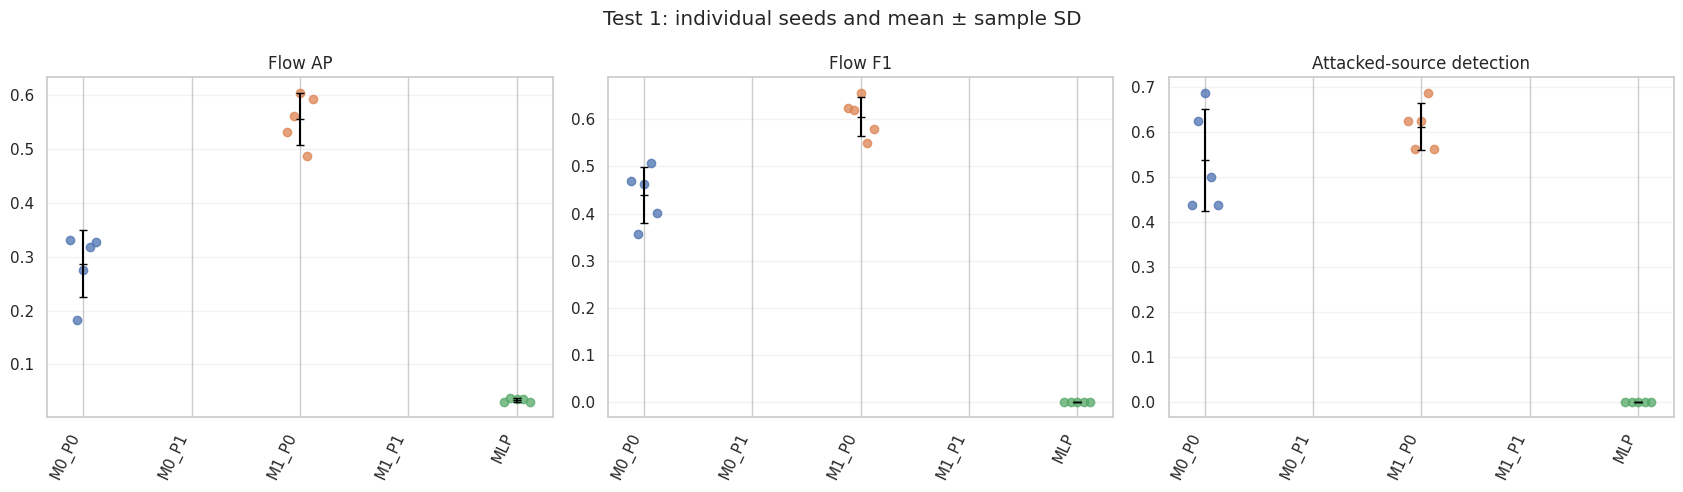

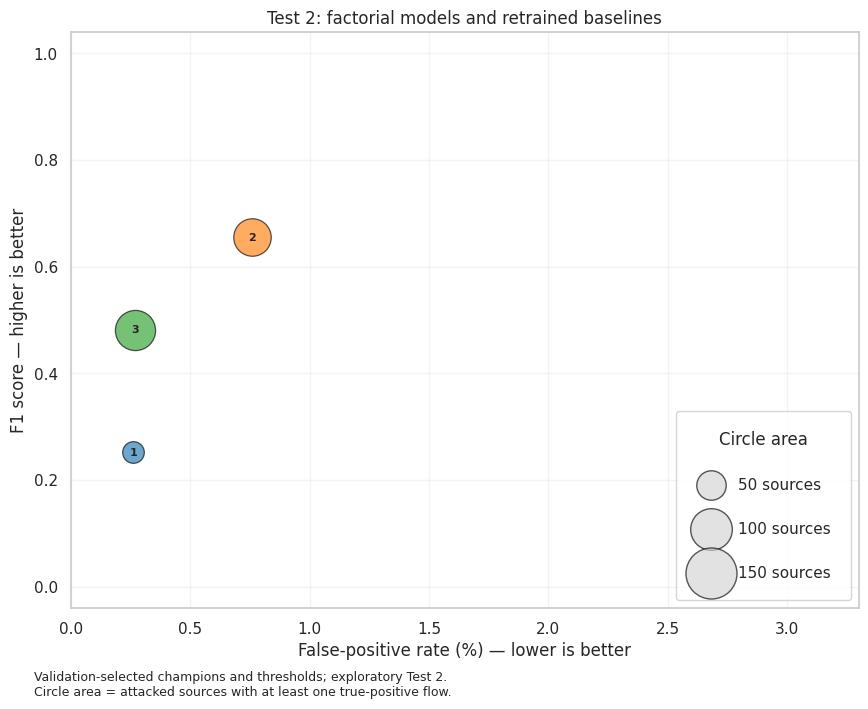

,model,seed,F1,Recall,FPR_percent,sources_detected,attacked_sources
0,M0_P0,99,0.25202,0.15744,0.26147,27,380
1,M1_P0,123,0.65510,0.61665,0.75639,81,380
2,MLP,2024,0.48100,0.34659,0.26886,93,380


Saved new baseline results: /content/drive/MyDrive/nids-mitre/results_baselines_dedup_historical_split_original_v1
Complete training runs: 5 / 5


In [12]:
model_order = list(reference_manifest['cells']) + list(MODEL_SPECS)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metric, title in zip(axes, ['AUC-PR', 'F1', 'source_detection_fraction'],
                            ['Flow AP', 'Flow F1', 'Attacked-source detection']):
    for position, name in enumerate(model_order):
        group = all_test1.loc[all_test1['model'].eq(name) & all_test1['status'].eq('complete')]
        values = pd.to_numeric(group.get(metric, pd.Series(dtype=float)), errors='coerce').dropna()
        if len(values):
            ax.scatter(position + np.linspace(-0.12, 0.12, len(values)), values, alpha=0.75)
            ax.errorbar(position, values.mean(), yerr=values.std() if len(values) > 1 else 0,
                        color='black', fmt='_', capsize=3)
    ax.set_xticks(range(len(model_order)), model_order, rotation=65, ha='right')
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Test 1: individual seeds and mean ± sample SD')
fig.tight_layout()
fig.savefig(OUTPUT / 'comparison_test1_seeds.png', dpi=200, bbox_inches='tight')
plt.show()

bubble = all_test2.loc[all_test2['status'].eq('complete')].copy()
assert bubble['model'].is_unique
bubble['model'] = pd.Categorical(bubble['model'], categories=model_order, ordered=True)
bubble = bubble.sort_values('model').reset_index(drop=True)
bubble['plot_id'] = np.arange(1, len(bubble) + 1)
bubble['FPR_percent'] = 100 * bubble['FPR']
palette = plt.get_cmap('tab20')
bubble_colors = {str(name): palette(i) for i, name in enumerate(model_order)}
AREA_PER_SOURCE = 9.0
fig, ax = plt.subplots(figsize=(15, 8))
for _, row in bubble.sort_values('sources_detected', ascending=False).iterrows():
    ax.scatter(row['FPR_percent'], row['F1'], s=AREA_PER_SOURCE * row['sources_detected'],
               color=bubble_colors[str(row['model'])], edgecolor='black', alpha=0.65, linewidth=0.9, zorder=3)
    ax.annotate(str(int(row['plot_id'])), (row['FPR_percent'], row['F1']),
                ha='center', va='center', fontsize=8, fontweight='bold', zorder=4)
handles = []
for _, row in bubble.iterrows():
    name = 'M1_P1 (retrained ST-GNN)' if row['model'] == 'M1_P1' else str(row['model'])
    label = (f'{int(row["plot_id"]):2d}. {name}\n'
             f'     seed {int(row["seed"])} | {int(row["sources_detected"])} sources')
    handles.append(Line2D([], [], linestyle='', marker='o', markersize=8,
                           color=bubble_colors[str(row['model'])], markeredgecolor='black', label=label))
legend = ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.02, 1),
                    frameon=False, fontsize=9, labelspacing=0.9)
ax.add_artist(legend)
size_handles = [ax.scatter([], [], s=AREA_PER_SOURCE * count, color='lightgray', edgecolor='black',
                            alpha=0.65, label=f'{count} sources') for count in (50, 100, 150)]
ax.legend(handles=size_handles, title='Circle area', loc='lower right', labelspacing=1.9, borderpad=1.3)
ax.set_xlabel('False-positive rate (%) — lower is better')
ax.set_ylabel('F1 score — higher is better')
ax.set_title('Test 2: factorial models and retrained baselines')
ax.set_ylim(-0.04, 1.04)
ax.set_xlim(0, max(3.3, float(bubble['FPR_percent'].max()) * 1.15) if len(bubble) else 3.3)
ax.grid(alpha=0.22)
ax.set_axisbelow(True)
fig.subplots_adjust(right=0.65, bottom=0.16)
fig.text(0.1, 0.05,
         'Validation-selected champions and thresholds; exploratory Test 2.\n'
         'Circle area = attacked sources with at least one true-positive flow.',
         ha='left', fontsize=9)
for extension in ('png', 'pdf'):
    fig.savefig(OUTPUT / f'comparison_test2_f1_fpr_sources.{extension}', dpi=220, bbox_inches='tight')
plt.show()
bubble.to_csv(OUTPUT / 'comparison_test2_bubble_data.csv', index=False)
display(bubble.reindex(columns=['model', 'seed', 'F1', 'Recall', 'FPR_percent', 'sources_detected', 'attacked_sources']).round(5))

write_json(OUTPUT / 'output_inventory.json', dict(
    manifest_sha256=MANIFEST_SHA256,
    reference_manifest_sha256=REFERENCE_MANIFEST_SHA256,
    completed_training_runs=int(training_status['status'].eq('complete').sum()),
    expected_training_runs=len(MODEL_SPECS) * len(SEEDS),
    champion_seeds=champion_seeds,
    artifacts={
        'manifest.json': 'Frozen protocol, implementation, data and software provenance',
        'runtime.json': 'Runtime device and hardware',
        'config_*.json': 'Per-model configuration and parameter counts',
        'training_status.csv': 'All 20 requested model/seed records, including failures',
        'MODEL/seed_N/history.csv': 'Epoch-level losses, validation AP and elapsed time',
        'MODEL/seed_N/checkpoint.pth': 'Best validation-AP checkpoint',
        'MODEL/seed_N/record.json': 'Completion status, validation metrics, threshold and checkpoint hash',
        'MODEL/seed_N/*_scores.npz': 'Aligned validation and test scores',
        'MODEL/seed_N/*_source_detection.csv': 'Attacked sources, including censored misses',
        'MODEL/seed_N/*_source_windows.csv': 'Source-window attack presence and alert activity',
        'MODEL/seed_N/*_daily_workload.csv': 'Calendar-day alert counts',
        'validation_all_seeds.csv': 'Validation results for all requested seeds',
        'champions_by_validation.csv': 'Validation-only champion-selection record',
        'test1_all_seeds.csv': 'New baseline Test 1 results',
        'test2_champions.csv': 'New baseline Test 2 champions',
        'comparison_test1_all_seeds.csv': 'Factorial and baseline Test 1 rows',
        'comparison_test1_summary.csv': 'Means, sample SDs, ranges and run counts',
        'comparison_test2_champions.csv': 'Factorial and baseline Test 2 champions',
        'test1_paired_vs_M1_P1.csv': 'Per-seed baseline minus ST-GNN metric differences',
        'test1_paired_summary_vs_M1_P1.csv': 'Paired summary with explicit denominators',
        'comparison_test2_source_1195_sensitivity.csv': 'Subset metrics at frozen thresholds',
        'comparison_test2_f1_fpr_sources.png': 'F1/FPR/source-count bubble chart',
    }))
print('Saved new baseline results:', OUTPUT)
print('Complete training runs:', int(training_status['status'].eq('complete').sum()), '/', len(training_status))
if not training_status['status'].eq('complete').all():
    print('Incomplete experiment: review training_status.csv; failed seeds remain in the tables.')